In [10]:
# data loading
import pandas as pd

df1 = pd.read_excel(r"D:\6Months\Project_2\Data\Medibuddy insurance data personal details.xlsx")
df1

,Policy no.,children,smoker,region
0,PLC157006,0,no,southwest
1,PLC157033,1,no,southwest
2,PLC157060,0,no,southwest
3,PLC157087,1,no,southwest
4,PLC157186,5,no,southwest
...,...,...,...,...
1333,PLC168400,1,yes,northeast
1334,PLC168436,0,yes,northeast
1335,PLC168634,2,yes,northeast
1336,PLC168652,0,yes,northeast


In [11]:
# data loading

df2 = pd.read_excel(r"D:\6Months\Project_2\Data\Medibuddy Insurance Data Price.xlsx")
df2

,Policy no.,age,sex,bmi,charges in INR
0,PLC156898,19,female,27.900,16884.92400
1,PLC156907,18,male,33.770,1725.55230
2,PLC156916,28,male,33.000,4449.46200
3,PLC156925,33,male,22.705,21984.47061
4,PLC156934,32,male,28.880,3866.85520
...,...,...,...,...,...
1333,PLC168895,50,male,30.970,10600.54830
1334,PLC168904,18,female,31.920,2205.98080
1335,PLC168913,18,female,36.850,1629.83350
1336,PLC168922,21,female,25.800,2007.94500


In [12]:
# merge two datasets

data = pd.merge(
    df1,df2,on="Policy no.",
    how = "inner"
)

In [13]:
data

,Policy no.,children,smoker,region,age,sex,bmi,charges in INR
0,PLC157006,0,no,southwest,23,male,34.400,1826.84300
1,PLC157033,1,no,southwest,19,male,24.600,1837.23700
2,PLC157060,0,no,southwest,56,male,40.300,10602.38500
3,PLC157087,1,no,southwest,30,female,32.400,4149.73600
4,PLC157186,5,no,southwest,19,female,28.600,4687.79700
...,...,...,...,...,...,...,...,...
1333,PLC168400,1,yes,northeast,39,male,29.925,22462.04375
1334,PLC168436,0,yes,northeast,18,female,21.660,14283.45940
1335,PLC168634,2,yes,northeast,42,male,24.605,21259.37795
1336,PLC168652,0,yes,northeast,29,female,21.850,16115.30450


In [14]:
# what is the size of dataset
data.shape

(1338, 8)

In [15]:
# how many columns in dataset
data.columns

Index(['Policy no.', 'children', 'smoker', 'region', 'age', 'sex', 'bmi',
       'charges in INR'],
      dtype='str')

In [16]:
#check  how many Nan or blanck

data.isnull().sum()

Policy no.        0
children          0
smoker            0
region            0
age               0
sex               0
bmi               0
charges in INR    0
dtype: int64

In [17]:
#check duplicated values

data.duplicated().sum()

np.int64(0)

In [18]:
# data info 

data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Policy no.      1338 non-null   str    
 1   children        1338 non-null   int64  
 2   smoker          1338 non-null   str    
 3   region          1338 non-null   str    
 4   age             1338 non-null   int64  
 5   sex             1338 non-null   str    
 6   bmi             1338 non-null   float64
 7   charges in INR  1338 non-null   float64
dtypes: float64(2), int64(2), str(4)
memory usage: 83.8 KB


In [20]:
# Checking unique values in sex columns

print("Gender:",data['sex'].unique())

# checking how may male or female
data['sex'].value_counts()

Gender: <StringArray>
['male', 'female']
Length: 2, dtype: str


sex
male      676
female    662
Name: count, dtype: int64

In [21]:
#checking unique values in smoker columns
print("Smoker:",data['smoker'].unique())

# checking how many smoker  or no smoker
data['smoker'].value_counts()

Smoker: <StringArray>
['no', 'yes']
Length: 2, dtype: str


smoker
no     1064
yes     274
Name: count, dtype: int64

In [22]:
#checking unique values in  regions
print("Region:",data['region'].unique())

# checking how may region in each
data['region'].value_counts()

Region: <StringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str


region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

In [23]:
#checking how many values
print("Children:",data['children'].unique())

# checking how may values
data['children'].value_counts()

Children: [0 1 5 2 3 4]


children
0    574
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64

In [24]:
#check statistical information
data.describe()

,children,age,bmi,charges in INR
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,1.094918,39.207025,30.663397,13270.422265
std,1.205493,14.049960,6.098187,12110.011237
min,0.000000,18.000000,15.960000,1121.873900
25%,0.000000,27.000000,26.296250,4740.287150
50%,1.000000,39.000000,30.400000,9382.033000
75%,2.000000,51.000000,34.693750,16639.912515
max,5.000000,64.000000,53.130000,63770.428010


In [25]:
Q1 = data["charges in INR"].quantile(0.25)

Q3 = data["charges in INR"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = data[
    (data["charges in INR"] < lower) |
    (data["charges in INR"] > upper)
]

print("Lower limit:", lower)
print("Upper limit:", upper)
print("Number of outliers:", len(outliers))

Lower limit: -13109.1508975
Upper limit: 34489.350562499996
Number of outliers: 139


In [26]:
outliers = data[data['charges in INR'] > upper]
outliers.head(10)

,Policy no.,children,smoker,region,age,sex,bmi,charges in INR
45,PLC159076,1,no,southwest,55,female,26.80,35160.13457
241,PLC167752,2,no,southwest,59,female,34.80,36910.60803
480,PLC166006,4,no,southeast,61,female,33.33,36580.28216
1065,PLC157069,0,yes,southwest,30,male,35.30,36837.46700
1066,PLC157159,2,yes,southwest,31,male,36.30,38711.00000
1067,PLC157168,0,yes,southwest,22,male,35.60,35585.57600
1068,PLC157204,1,yes,southwest,28,male,36.40,51194.55914
1069,PLC157249,0,yes,southwest,60,male,39.90,48173.36100
1071,PLC157654,2,yes,southwest,37,female,34.80,39836.51900
1072,PLC157744,2,yes,southwest,64,female,31.30,47291.05500


In [27]:
outliers['smoker'].value_counts()

smoker
yes    136
no       3
Name: count, dtype: int64

In [28]:
outliers['charges in INR'].mean()

np.float64(42103.94720582734)

In [29]:
outliers[['age','bmi','charges in INR']].mean()

age                  41.079137
bmi                  35.564604
charges in INR    42103.947206
dtype: float64

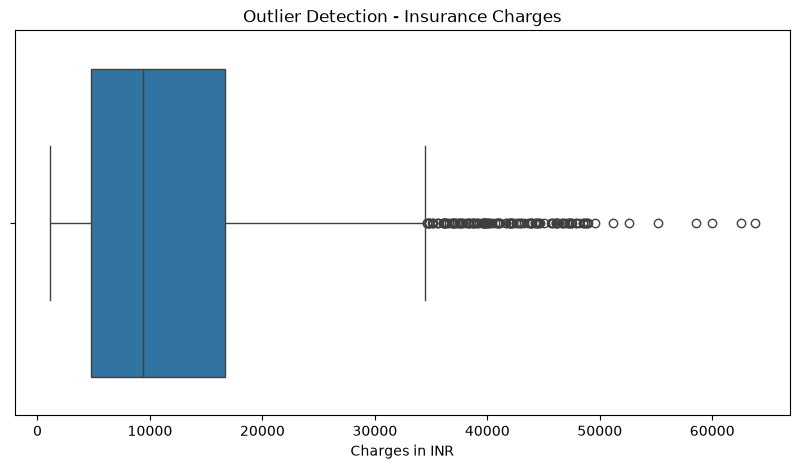

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.boxplot(
    x=data["charges in INR"]
)

plt.title("Outlier Detection - Insurance Charges")

plt.xlabel("Charges in INR")

plt.show()

In [31]:
#Extract outlier records
outliers = data[data['charges in INR'] > upper ]
print('Total Outliers:',len(outliers))
outliers.head()

Total Outliers: 139


,Policy no.,children,smoker,region,age,sex,bmi,charges in INR
45,PLC159076,1,no,southwest,55,female,26.80,35160.13457
241,PLC167752,2,no,southwest,59,female,34.80,36910.60803
480,PLC166006,4,no,southeast,61,female,33.33,36580.28216
1065,PLC157069,0,yes,southwest,30,male,35.30,36837.46700
1066,PLC157159,2,yes,southwest,31,male,36.30,38711.00000


In [33]:
# Retain all original records
df_cleaned = data.copy()

print("Original dataset shape:", data.shape)
print("Dataset after outlier investigation:", df_cleaned.shape)

Original dataset shape: (1338, 8)
Dataset after outlier investigation: (1338, 8)


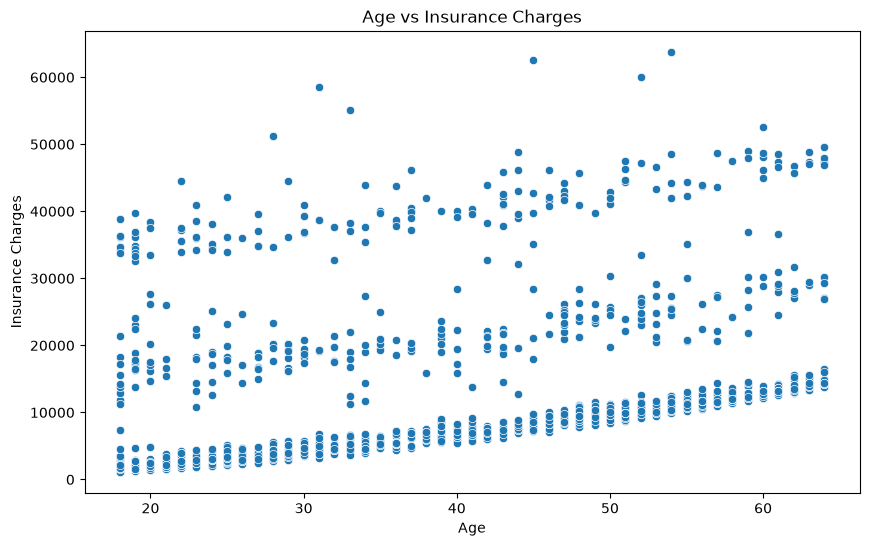

In [34]:
##Exploratory Data Analysis (EDA)

# 1. Age vs Insurance Charges

plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df_cleaned,
    x = 'age',
    y = 'charges in INR'
)

plt.title("Age vs Insurance Charges")
plt.xlabel("Age")
plt.ylabel("Insurance Charges")
plt.show()

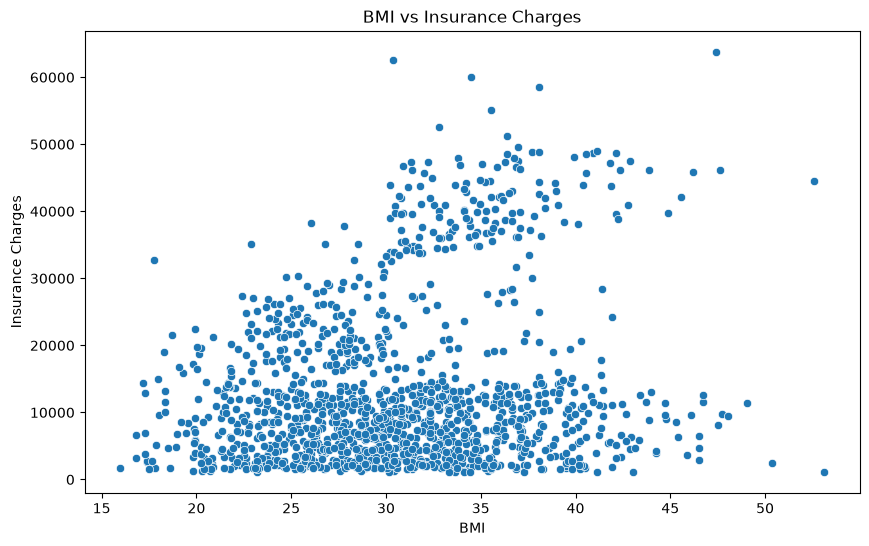

In [35]:
# BMI Vs Insurance Charges
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df_cleaned,
    x = 'bmi',
    y = 'charges in INR'
)

plt.title("BMI vs Insurance Charges")
plt.xlabel("BMI")
plt.ylabel("Insurance Charges")
plt.show()

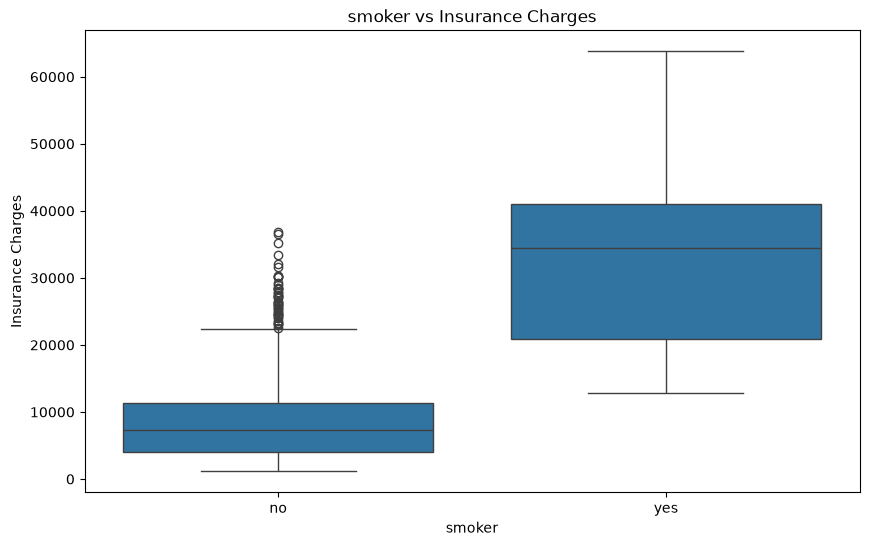

In [36]:
# smoker Vs Insurance Charges
plt.figure(figsize=(10,6))
sns.boxplot(
    data=df_cleaned,
    x = 'smoker',
    y = 'charges in INR'
)

plt.title("smoker vs Insurance Charges")
plt.xlabel("smoker")
plt.ylabel("Insurance Charges")
plt.show()

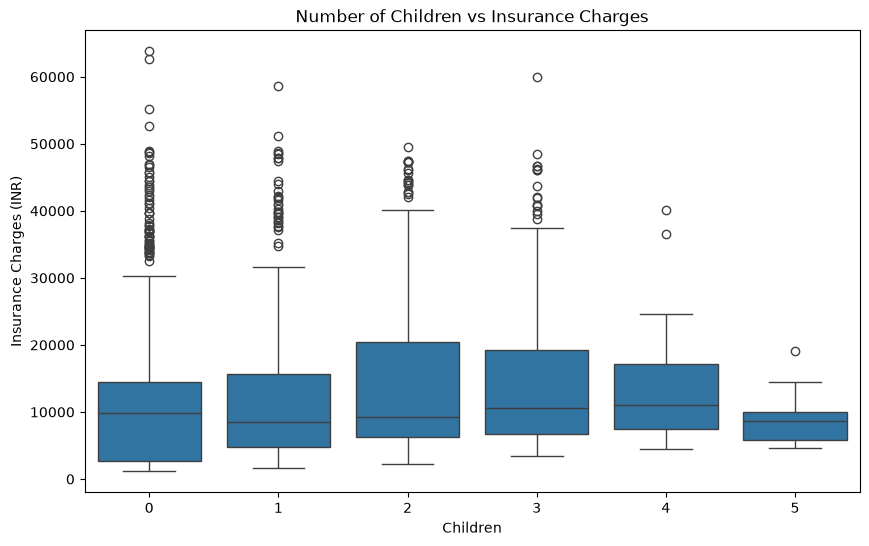

In [37]:
#Children Vs Insurance Charges

plt.figure(figsize=(10,6))

sns.boxplot(
    data = df_cleaned,
    x = 'children',
    y = 'charges in INR'
)

plt.title("Number of Children vs Insurance Charges")
plt.xlabel("Children")
plt.ylabel("Insurance Charges (INR)")
plt.show()

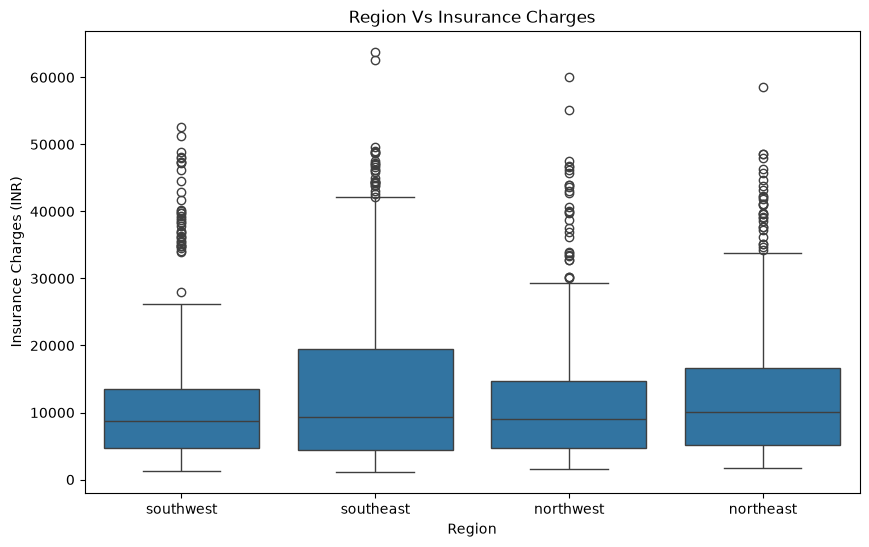

In [38]:
#Region Vs Insurance Charges

plt.figure(figsize=(10,6))
sns.boxplot(
    data = df_cleaned,
    x = 'region',
    y = 'charges in INR'
)
plt.title("Region Vs Insurance Charges")
plt.xlabel("Region")
plt.ylabel("Insurance Charges (INR)")
plt.show()

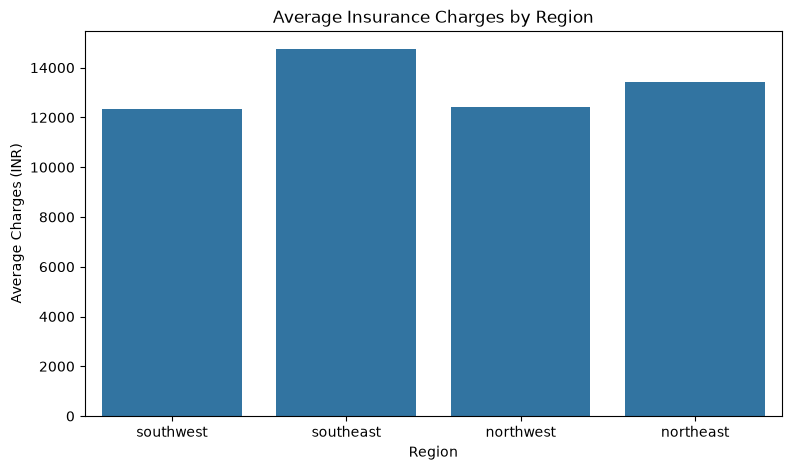

In [39]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_cleaned,
    x="region",
    y="charges in INR",
    estimator="mean",
    errorbar=None
)

plt.title("Average Insurance Charges by Region")
plt.xlabel("Region")
plt.ylabel("Average Charges (INR)")

plt.show()

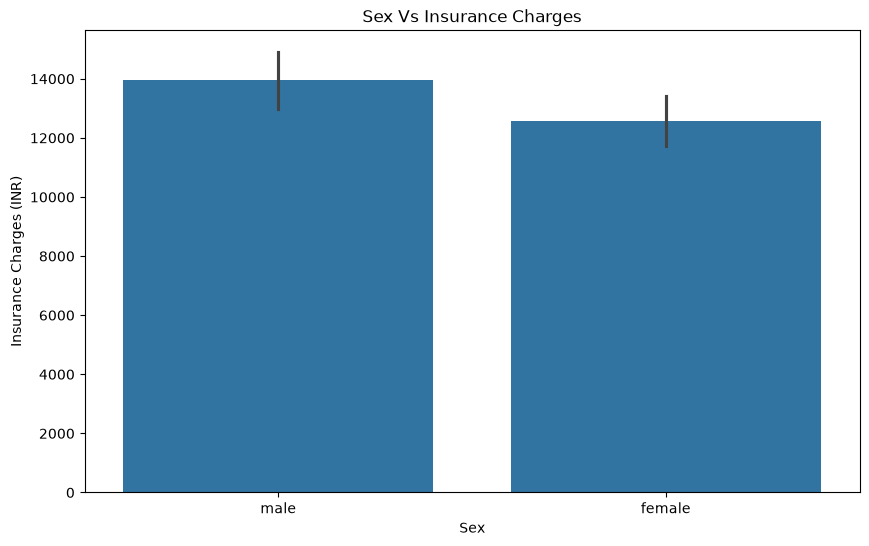

In [40]:
#Gender Vs Insurance Charges 

plt.figure(figsize=(10,6))
sns.barplot(
    data = df_cleaned,
    x = 'sex',
    y = 'charges in INR'
)
plt.title("Sex Vs Insurance Charges")
plt.xlabel("Sex")
plt.ylabel("Insurance Charges (INR)")
plt.show()

In [41]:
#Correlation Analysis
df_cleaned.select_dtypes(include=['int64','float64']).columns

Index(['children', 'age', 'bmi', 'charges in INR'], dtype='str')

In [42]:
correlation = df_cleaned.select_dtypes(
    include=['int64','float64']
).corr()

correlation

,children,age,bmi,charges in INR
children,1.000000,0.042469,0.012759,0.067998
age,0.042469,1.000000,0.109272,0.299008
bmi,0.012759,0.109272,1.000000,0.198341
charges in INR,0.067998,0.299008,0.198341,1.000000


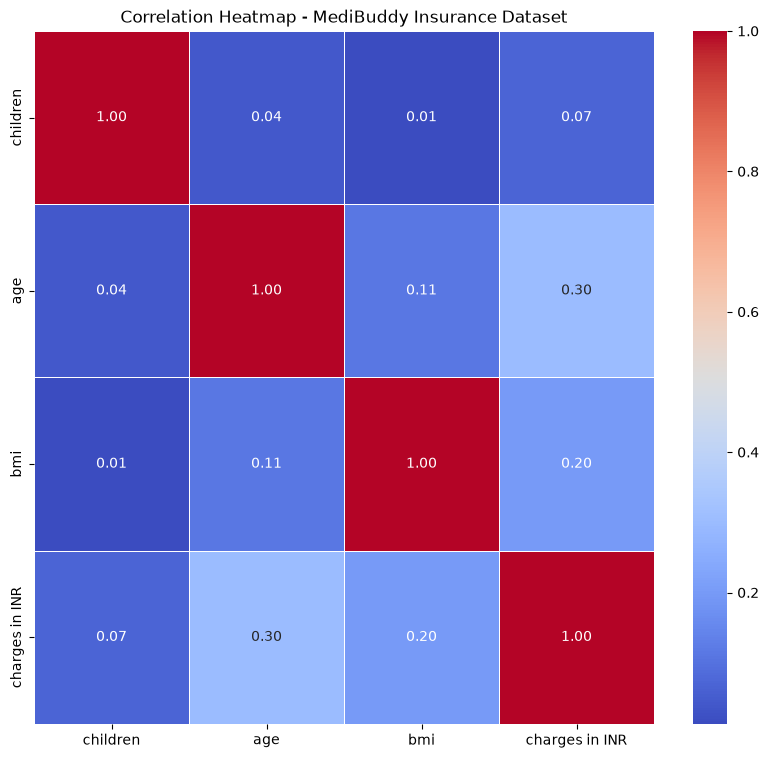

In [43]:
plt.figure(figsize=(10,9))
sns.heatmap(
    correlation,
    annot = True,
    cmap = "coolwarm",
    fmt = ".2f",
    linewidths = 0.5
)
plt.title("Correlation Heatmap - MediBuddy Insurance Dataset")
plt.show()

In [44]:
correlation["charges in INR"].sort_values(ascending=False)

charges in INR    1.000000
age               0.299008
bmi               0.198341
children          0.067998
Name: charges in INR, dtype: float64

In [45]:
# Feature Engineering

# 1.handle missing values

df_cleaned.isnull().sum()

Policy no.        0
children          0
smoker            0
region            0
age               0
sex               0
bmi               0
charges in INR    0
dtype: int64

In [46]:
print('Total missing values:',df_cleaned.isnull().sum().sum())

Total missing values: 0


In [47]:
# 2.Remove duplicate records

df_cleaned.duplicated().sum()

np.int64(0)

In [48]:
df_cleaned.duplicated().sum() # after removig duplicates

np.int64(0)

In [49]:
# 3.Drop unnecessary columns

df_cleaned.columns

Index(['Policy no.', 'children', 'smoker', 'region', 'age', 'sex', 'bmi',
       'charges in INR'],
      dtype='str')

In [50]:
df_cleaned = df_cleaned.drop(columns=["Policy no."])

print("Dataset shape:",df_cleaned.shape)
print(df_cleaned.head())

Dataset shape: (1338, 7)
   children smoker     region  age     sex   bmi  charges in INR
0         0     no  southwest   23    male  34.4        1826.843
1         1     no  southwest   19    male  24.6        1837.237
2         0     no  southwest   56    male  40.3       10602.385
3         1     no  southwest   30  female  32.4        4149.736
4         5     no  southwest   19  female  28.6        4687.797


In [51]:
# identify numerical and Categorical features.

numerical_columns = df_cleaned.select_dtypes(
    include=['int64','float64']
).columns

print("Numerical Columns:")
print(numerical_columns.tolist())

Numerical Columns:
['children', 'age', 'bmi', 'charges in INR']


In [52]:
categorical_columns = df_cleaned.select_dtypes(
    include=['object','category']
).columns

print("Categorical Columns:")
print(categorical_columns.tolist())

Categorical Columns:
['smoker', 'region', 'sex']


C:\Users\kbdpa.TRIVEDI\AppData\Local\Temp\ipykernel_6796\2285224051.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df_cleaned.select_dtypes(


In [53]:
print("Numerical Columns:")
print(numerical_columns.tolist())

print("Categorical Columns:")
print(categorical_columns.tolist())

Numerical Columns:
['children', 'age', 'bmi', 'charges in INR']
Categorical Columns:
['smoker', 'region', 'sex']


In [54]:
#Encode Categorical Variables

import pandas as pd

df_encoded = df_cleaned.copy()

df_encoded = pd.get_dummies(
    df_cleaned,
    columns=["sex", "smoker", "region"],
    drop_first=True,
    dtype=int
)

print("Encoded Dataset:")
display(df_encoded.head())

Encoded Dataset:


,children,age,bmi,charges in INR,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,0,23,34.4,1826.843,1,0,0,0,1
1,1,19,24.6,1837.237,1,0,0,0,1
2,0,56,40.3,10602.385,1,0,0,0,1
3,1,30,32.4,4149.736,0,0,0,0,1
4,5,19,28.6,4687.797,0,0,0,0,1


In [55]:
df_encoded.shape

(1338, 9)

In [56]:
print("Encoded Dataset Shape:", df_encoded.shape)

print("\nEncoded Columns:")
print(df_encoded.columns.tolist())

Encoded Dataset Shape: (1338, 9)

Encoded Columns:
['children', 'age', 'bmi', 'charges in INR', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


In [57]:
df_cleaned

,children,smoker,region,age,sex,bmi,charges in INR
0,0,no,southwest,23,male,34.400,1826.84300
1,1,no,southwest,19,male,24.600,1837.23700
2,0,no,southwest,56,male,40.300,10602.38500
3,1,no,southwest,30,female,32.400,4149.73600
4,5,no,southwest,19,female,28.600,4687.79700
...,...,...,...,...,...,...,...
1333,1,yes,northeast,39,male,29.925,22462.04375
1334,0,yes,northeast,18,female,21.660,14283.45940
1335,2,yes,northeast,42,male,24.605,21259.37795
1336,0,yes,northeast,29,female,21.850,16115.30450


In [58]:
df_cleaned['region'].value_counts()


region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

In [59]:
# Display the first five records
print("Encoded Dataset:")
display(df_encoded.head())

# Display dataset information
print("\nDataset Shape:", df_encoded.shape)

print("\nEncoded Column Names:")
print(df_encoded.columns.tolist())

print("\nData Types:")
print(df_encoded.dtypes)


Encoded Dataset:


,children,age,bmi,charges in INR,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,0,23,34.4,1826.843,1,0,0,0,1
1,1,19,24.6,1837.237,1,0,0,0,1
2,0,56,40.3,10602.385,1,0,0,0,1
3,1,30,32.4,4149.736,0,0,0,0,1
4,5,19,28.6,4687.797,0,0,0,0,1



Dataset Shape: (1338, 9)

Encoded Column Names:
['children', 'age', 'bmi', 'charges in INR', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']

Data Types:
children              int64
age                   int64
bmi                 float64
charges in INR      float64
sex_male              int64
smoker_yes            int64
region_northwest      int64
region_southeast      int64
region_southwest      int64
dtype: object


In [60]:
#Feature Selection

X = df_encoded.drop(columns=['charges in INR']) # Input feature 
y = df_encoded['charges in INR'] # output feature

In [61]:
X.shape # input variable 

(1338, 8)

In [62]:
y.shape # output variable 

(1338,)

In [64]:
# train test split
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [65]:
# Display dataset shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1070, 8)
X_test shape: (268, 8)
y_train shape: (1070,)
y_test shape: (268,)


In [66]:
#Feature scalling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.fit_transform(X_test)

print("Traing data shape:",X_train_scaled.shape)
print("Testing data shape:",X_test_scaled.shape)

Traing data shape: (1070, 8)
Testing data shape: (268, 8)


In [67]:
# final preprocessing verification

print("Orignal Training Data Shape:",X_train.shape)
print("Orignal Testing Data Shape:",X_test.shape)

print("\nScaled Training Data Shape:",X_train_scaled.shape)
print("Scaled Testing Data Shape:",X_test_scaled.shape)

print("\n Training Target Shape:",y_train.shape)
print("Testing Target Shape:",y_test.shape)

print("\nMissing Values in training Data:",
      pd.DataFrame(X_train_scaled).isnull().sum().sum())

print("Missing values in Testing Data:",
      pd.DataFrame(X_test_scaled).isnull().sum().sum())

Orignal Training Data Shape: (1070, 8)
Orignal Testing Data Shape: (268, 8)

Scaled Training Data Shape: (1070, 8)
Scaled Testing Data Shape: (268, 8)

 Training Target Shape: (1070,)
Testing Target Shape: (268,)

Missing Values in training Data: 0
Missing values in Testing Data: 0


In [68]:
import numpy as np

print("\nInfinite Values in Training Data:",
      np.isinf(X_train_scaled).sum())

print("Infinite Values in Testing Data:",
      np.isinf(X_test_scaled).sum())


Infinite Values in Training Data: 0
Infinite Values in Testing Data: 0


In [69]:
# Machine Learning Model Building

# 1.Linear Regression Model

from sklearn.linear_model import LinearRegression

#create the model
lr_model = LinearRegression()

# train the model
lr_model.fit(X_train_scaled,y_train)

# Predict insurance charges
y_pred_lr = lr_model.predict(X_test_scaled)

#Display first 10 predictions
print("First 10 Predicted Insurance Charges:")
print(y_pred_lr[:10])

First 10 Predicted Insurance Charges:
[14341.57513795  7216.91476492  4109.48276402 35521.30884209
  1178.02604027 33314.73712521  1109.14352052 12533.85886333
 39658.82918755 13589.19036127]


In [70]:
# Linear Regression model  Evaluate

from sklearn.metrics import(
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

#Calculate evaluation metrics
mae = mean_absolute_error(y_test,y_pred_lr)
mse = mean_squared_error(y_test,y_pred_lr)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred_lr)

#Display results
print("Linear Regression Model Performance")
print("MAE:",mae)
print("MSE:",mse)
print("RMSE:",rmse)
print("R2 Score:",r2)

Linear Regression Model Performance
MAE: 4165.063879782091
MSE: 38146488.086312585
RMSE: 6176.28432686778
R2 Score: 0.7315467037485839


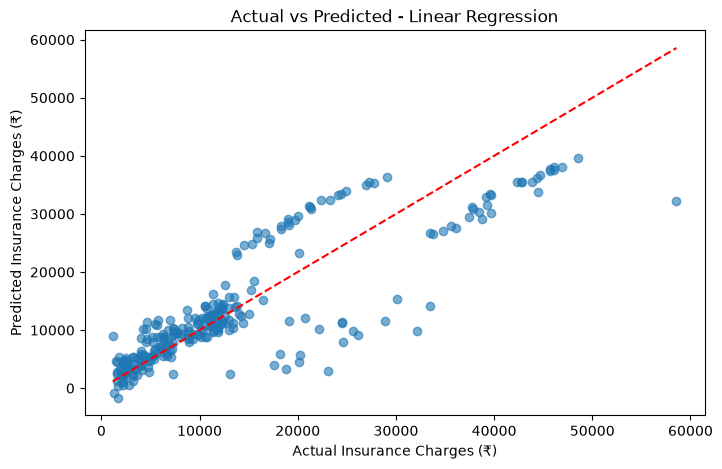

In [71]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_lr, alpha=0.6)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Insurance Charges (₹)")
plt.ylabel("Predicted Insurance Charges (₹)")
plt.title("Actual vs Predicted - Linear Regression")

plt.show()

In [72]:
# Decision Tree Regression 

from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    random_state=42,
    max_depth=5
)

dt_model.fit(X_train,y_train)

y_pred_dt = dt_model.predict(X_test)

print("First 10 Decision Tree Predictions:")
print(y_pred_dt[:10])

First 10 Decision Tree Predictions:
[12325.5957869   6581.33054621  2477.91550063 47254.32290033
  3620.2945     24300.52650258  2477.91550063 12325.5957869
 47254.32290033 14141.12346485]


In [73]:
# Decision Regression model  Evaluate

from sklearn.metrics import(
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

#Calculate evaluation metrics
mae = mean_absolute_error(y_test,y_pred_dt)
mse = mean_squared_error(y_test,y_pred_dt)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred_dt)

#Display results
print("Decision Regression Model Performance")
print("MAE:",mae)
print("MSE:",mse)
print("RMSE:",rmse)
print("R2 Score:",r2)

Decision Regression Model Performance
MAE: 2507.456173422105
MSE: 20845690.920227442
RMSE: 4565.708151013098
R2 Score: 0.8532998784183958


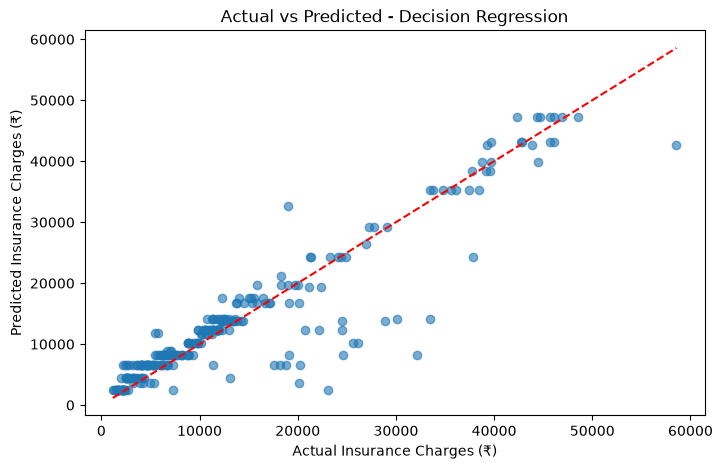

In [74]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_dt, alpha=0.6)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Insurance Charges (₹)")
plt.ylabel("Predicted Insurance Charges (₹)")
plt.title("Actual vs Predicted - Decision Regression")

plt.show()

In [75]:
# Random Forest Regression
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    max_depth = 10
)

rf_model.fit(X_train,y_train)

y_pred_rf = rf_model.predict(X_test)

print("First 10  Random Forest Predictions:")
print(y_pred_rf[:10])

First 10  Random Forest Predictions:
[12510.65569585  6124.96660326  2126.54544681 43242.68967224
  5829.53056381 23613.88661907  2371.79639367 14906.73967377
 47564.95280093 12354.74533344]


In [76]:
# Random Forest  Regression model  Evaluate

from sklearn.metrics import(
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

#Calculate evaluation metrics
mae = mean_absolute_error(y_test,y_pred_rf)
mse = mean_squared_error(y_test,y_pred_rf)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred_rf)

#Display results
print("Random Forest Regression Model Performance")
print("MAE:",mae)
print("MSE:",mse)
print("RMSE:",rmse)
print("R2 Score:",r2)

Random Forest Regression Model Performance
MAE: 2567.3513257053955
MSE: 22021747.536080915
RMSE: 4692.733482319331
R2 Score: 0.8450234605633683


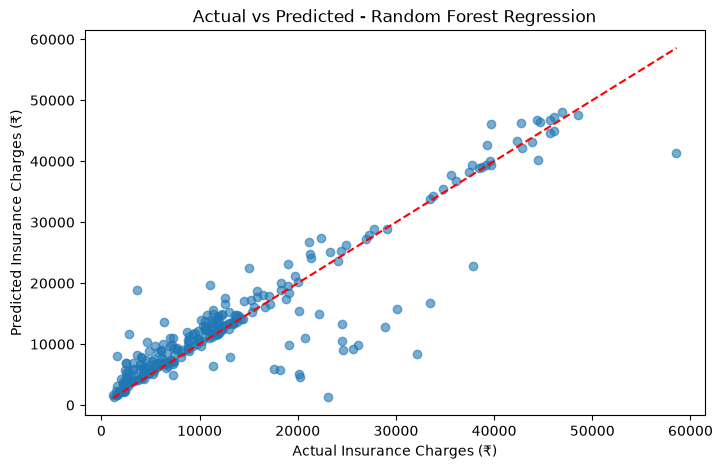

In [77]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_rf, alpha=0.6)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Insurance Charges (₹)")
plt.ylabel("Predicted Insurance Charges (₹)")
plt.title("Actual vs Predicted - Random Forest Regression")

plt.show()

In [78]:
# Gradient Boosting Regressor

from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth = 3,
    random_state=42
)

gb_model.fit(X_train,y_train)

y_pred_gb = gb_model.predict(X_test)

print("First 10 GradientBoostingRegressor Predictions:")
print(y_pred_gb[:10])

First 10 GradientBoostingRegressor Predictions:
[12687.09221252  7009.807329    3375.35680339 44382.04282933
  4230.95571137 24026.82869372  3129.51305389 12137.97141163
 47349.64111166 14094.00337279]


In [79]:
# GradientBoosting  Regression model  Evaluate

from sklearn.metrics import(
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

#Calculate evaluation metrics
mae = mean_absolute_error(y_test,y_pred_gb)
mse = mean_squared_error(y_test,y_pred_gb)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred_gb)

#Display results
print("GradientBoosting Regression Model Performance")
print("MAE:",mae)
print("MSE:",mse)
print("RMSE:",rmse)
print("R2 Score:",r2)

GradientBoosting Regression Model Performance
MAE: 2352.747616739391
MSE: 19164350.41483129
RMSE: 4377.71063626084
R2 Score: 0.8651321970259


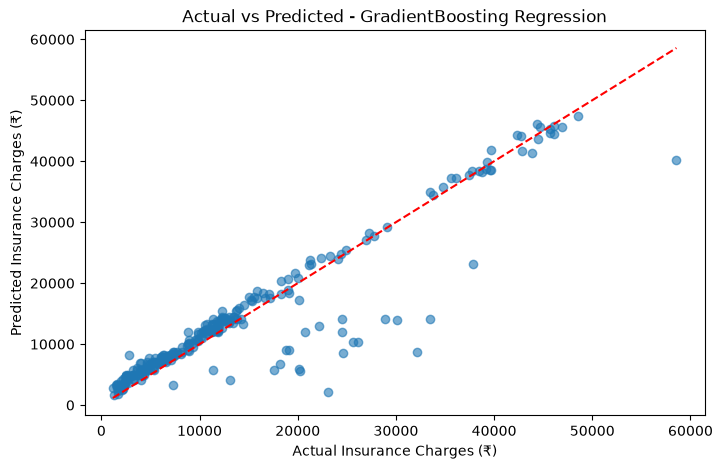

In [80]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_gb, alpha=0.6)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Insurance Charges (₹)")
plt.ylabel("Predicted Insurance Charges (₹)")
plt.title("Actual vs Predicted - GradientBoosting Regression")

plt.show()

In [81]:
# XGBoost Regression

# Step 16: XGBoost Regression

from xgboost import XGBRegressor

# Create the model
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    objective="reg:squarederror"
)

# Train the model
xgb_model.fit(X_train, y_train)

# Predict insurance charges
y_pred_xgb = xgb_model.predict(X_test)

# Display first 10 predictions
print("First 10 XGBoost Predictions:")
print(y_pred_xgb[:10])

First 10 XGBoost Predictions:
[12611.898   6929.426   3268.189  44362.215   4315.706  24087.168
  3193.6553 12081.29   47595.46   14073.398 ]


In [82]:
# GradientBoosting  Regression model  Evaluate

from sklearn.metrics import(
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

#Calculate evaluation metrics
mae = mean_absolute_error(y_test,y_pred_xgb)
mse = mean_squared_error(y_test,y_pred_xgb)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred_xgb)

#Display results
print("GradientBoosting Regression Model Performance")
print("MAE:",mae)
print("MSE:",mse)
print("RMSE:",rmse)
print("R2 Score:",r2)

GradientBoosting Regression Model Performance
MAE: 2332.109985921671
MSE: 19116767.518620133
RMSE: 4372.272580548945
R2 Score: 0.8654670583977824


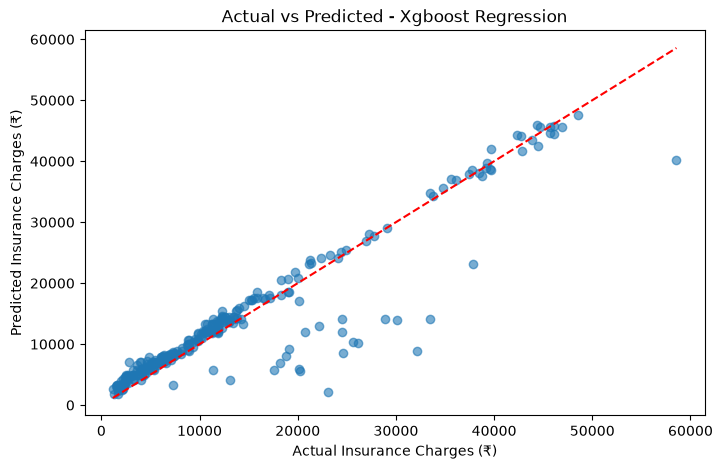

In [83]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_xgb, alpha=0.6)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Insurance Charges (₹)")
plt.ylabel("Predicted Insurance Charges (₹)")
plt.title("Actual vs Predicted - Xgboost Regression")

plt.show()

In [84]:
#Model Evaluation and Comparison

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np
import pandas as pd

# Store all models and predictions
models = {
    "Linear Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb,
    "XGBoost": y_pred_xgb
}

# Create an empty list
results = []

# Evaluate each model
for model_name, predictions in models.items():

    mae = mean_absolute_error(y_test, predictions)

    mse = mean_squared_error(y_test, predictions)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Create comparison DataFrame
model_comparison = pd.DataFrame(results)

# Display results
print("Machine Learning Model Comparison:")
display(model_comparison.round(4))

Machine Learning Model Comparison:


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,4165.0639,3.814649e+07,6176.2843,0.7315
1,Decision Tree,2507.4562,2.084569e+07,4565.7082,0.8533
2,Random Forest,2567.3513,2.202175e+07,4692.7335,0.8450
3,Gradient Boosting,2352.7476,1.916435e+07,4377.7106,0.8651
4,XGBoost,2332.1100,1.911677e+07,4372.2726,0.8655


In [85]:
# find the best performing model

best_model = model_comparison.sort_values(
    by="R2 Score",
    ascending=False
).iloc[0]

print("Best Performing Model:", best_model["Model"])
print("Best R2 Score:", best_model["R2 Score"])
print("MAE:", best_model["MAE"])
print("RMSE:", best_model["RMSE"])

Best Performing Model: XGBoost
Best R2 Score: 0.8654670583977824
MAE: 2332.109985921671
RMSE: 4372.272580548945


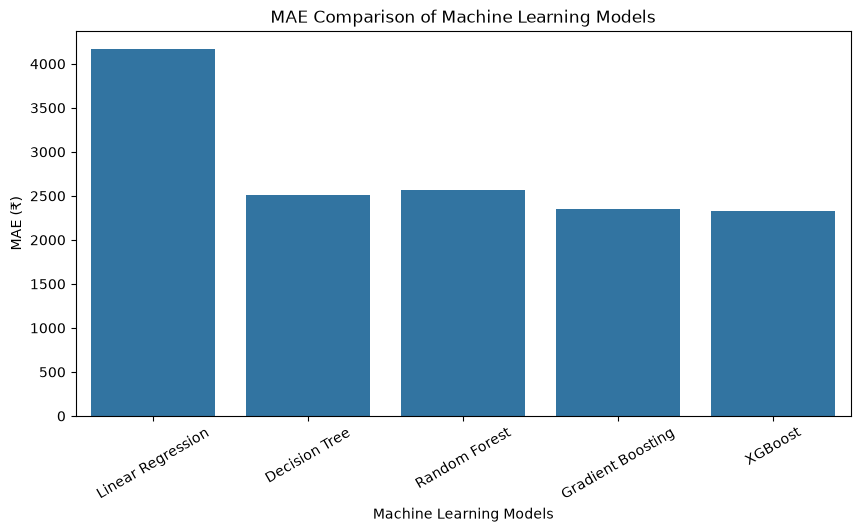

In [86]:
# Model Performance Visualization

# MAE Comparison

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="MAE"
)

plt.title("MAE Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("MAE (₹)")
plt.xticks(rotation=30)

plt.show()

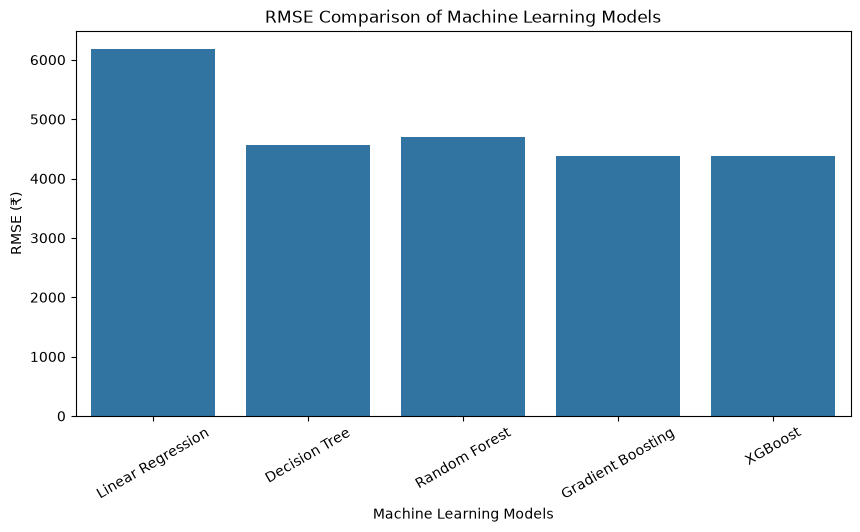

In [87]:
# RMSE Comparison

plt.figure(figsize=(10, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="RMSE"
)

plt.title("RMSE Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("RMSE (₹)")
plt.xticks(rotation=30)

plt.show()

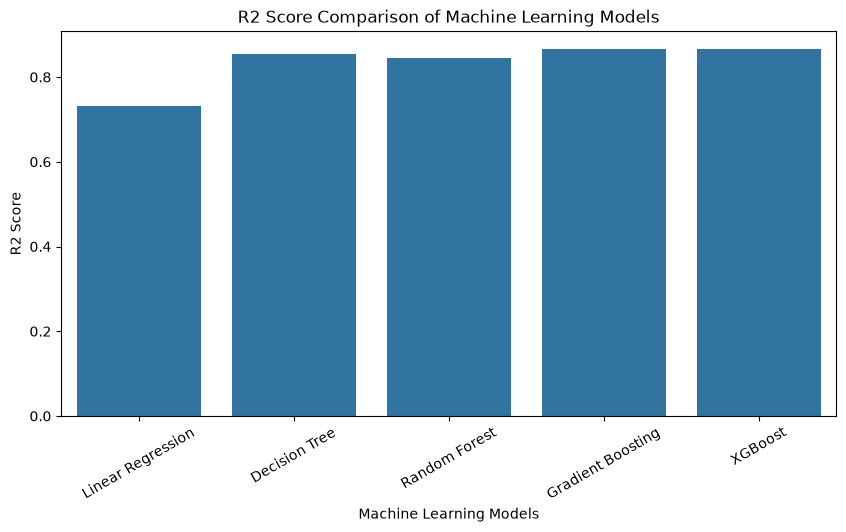

In [88]:
# R2 Score Comparison

plt.figure(figsize=(10, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="R2 Score"
)

plt.title("R2 Score Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=30)

plt.show()

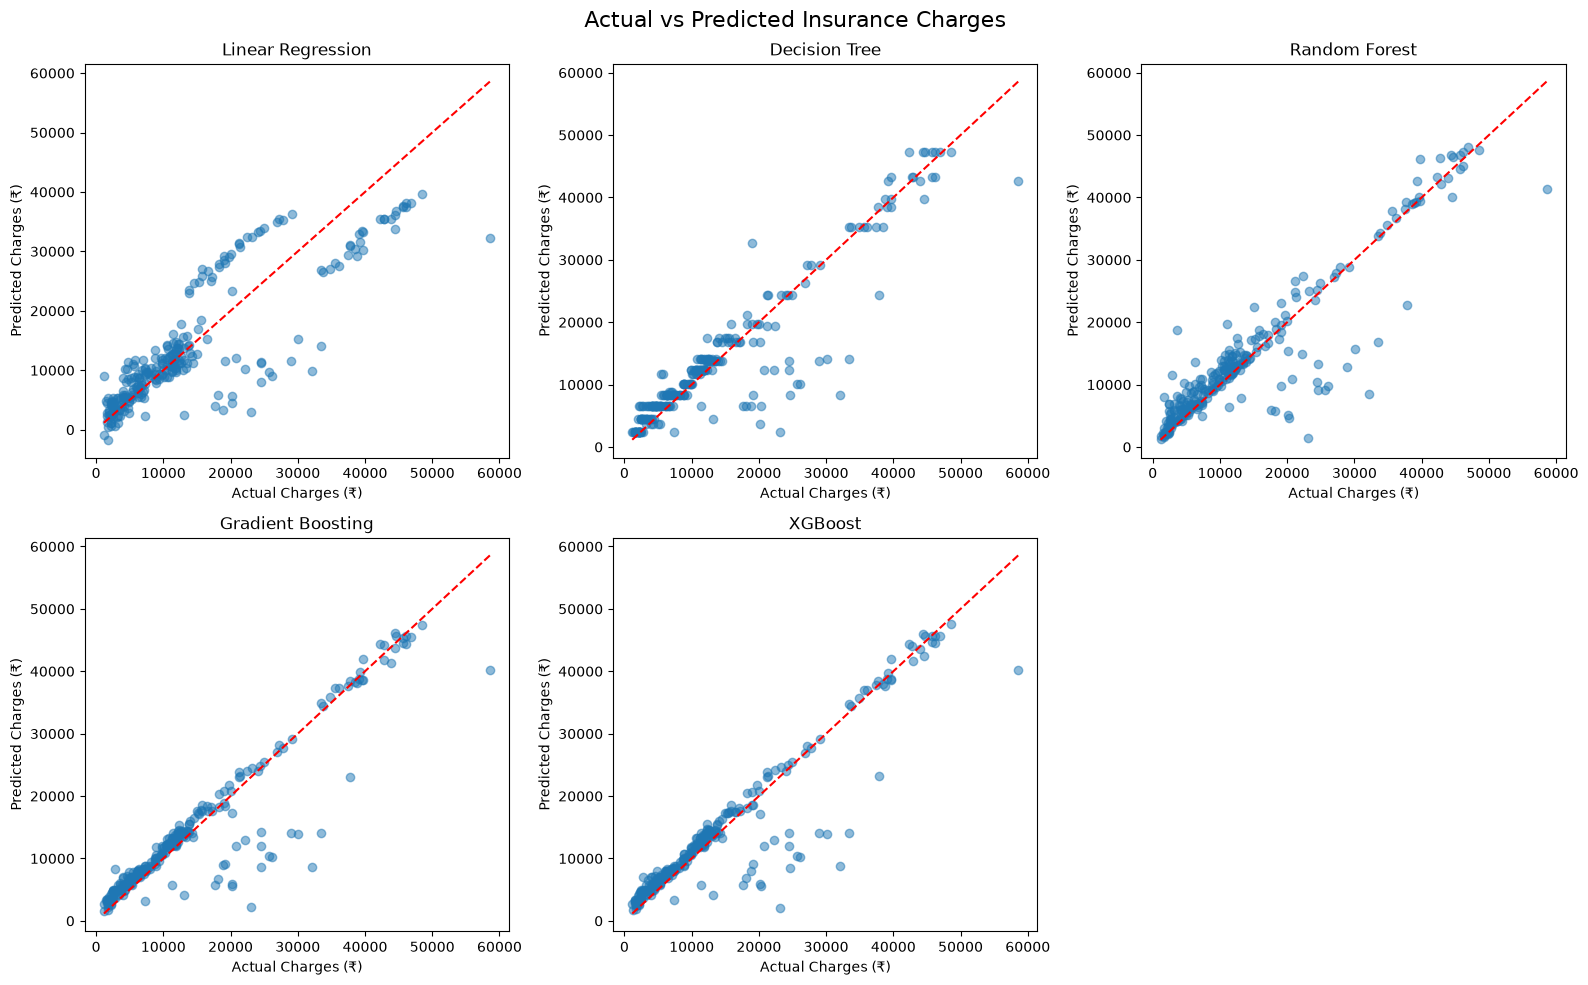

In [89]:
# Actual vs Predicted Comparison for All Models

# Step 19: Actual vs Predicted Comparison

import matplotlib.pyplot as plt

predictions = {
    "Linear Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb,
    "XGBoost": y_pred_xgb
}

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, (model_name, predictions_model) in enumerate(predictions.items()):

    axes[i].scatter(
        y_test,
        predictions_model,
        alpha=0.5
    )

    axes[i].plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        "r--"
    )

    axes[i].set_title(model_name)
    axes[i].set_xlabel("Actual Charges (₹)")
    axes[i].set_ylabel("Predicted Charges (₹)")

# Remove unused subplot
fig.delaxes(axes[5])

plt.suptitle("Actual vs Predicted Insurance Charges", fontsize=16)

plt.tight_layout()
plt.show()

In [90]:
#Feature Importance Analysis


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importance
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display feature importance
print("Random Forest Feature Importance:")
display(feature_importance)

Random Forest Feature Importance:


,Feature,Importance
4,smoker_yes,0.637733
2,bmi,0.197379
1,age,0.126362
0,children,0.019457
5,region_northwest,0.005721
6,region_southeast,0.004933
3,sex_male,0.004922
7,region_southwest,0.003493


In [91]:
best_model = xgb_model
y_pred_best = best_model.predict(X_test)

In [92]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV

xgb = XGBRegressor(
    objective = "reg:squarederror",
    random_state = 42,
    n_jobs = -1
)

param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [2, 3, 4, 5, 6],
    "min_child_weight": [1, 3, 5],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "gamma": [0, 0.1, 0.2],
    "reg_alpha": [0, 0.01, 0.1],
    "reg_lambda": [1, 1.5, 2]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=20,
    cv=5,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train, y_train)

print("Best Parameters:")
print(xgb_search.best_params_)

print("\nBest Cross Validation MAE:")
print(-xgb_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters:
{'subsample': 1.0, 'reg_lambda': 1, 'reg_alpha': 0.01, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 2, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.7}

Best Cross Validation MAE:
2491.2926743953167


In [93]:
best_xgb_model = xgb_search.best_estimator_

y_pred_xgb_tuned = best_xgb_model.predict(X_test)

In [94]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("Tuned XGBoost Model Performance")

print("MAE:", mean_absolute_error(y_test, y_pred_xgb_tuned))

print("MSE:", mean_squared_error(y_test, y_pred_xgb_tuned))

print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_xgb_tuned)))

print("R2 Score:", r2_score(y_test, y_pred_xgb_tuned))

Tuned XGBoost Model Performance
MAE: 2399.291173009183
MSE: 20126872.791011646
RMSE: 4486.298339501247
R2 Score: 0.8583585117519974


In [97]:
# Select the best-performing model
best_model = xgb_model

# Generate predictions
y_pred_best = best_model.predict(X_test)

print("Final Model: XGBoosting")
print("MAE:", mean_absolute_error(y_test, y_pred_best))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_best)))
print("R2 Score:", r2_score(y_test, y_pred_best))

Final Model: XGBoosting
MAE: 2332.109985921671
RMSE: 4372.272580548945
R2 Score: 0.8654670583977824


In [98]:
# Save final model using Joblib

import joblib

joblib.dump(best_model, "medibuddy_best_model.pkl")

print("Model saved successfully!")


Model saved successfully!


In [99]:
loaded_model = joblib.load("medibuddy_best_model.pkl")

# Make predictions using the loaded model
test_predictions = loaded_model.predict(X_test)

print("Loaded model R2 Score:", r2_score(y_test, test_predictions))

Loaded model R2 Score: 0.8654670583977824


In [100]:
# Create a new customer input

import pandas as pd

new_customer = pd.DataFrame({
    "children": [2],
    "age": [30],
    "bmi": [27.5],
    "sex_male": [1],
    "smoker_yes": [0],
    "region_northwest": [0],
    "region_southeast": [1],
    "region_southwest": [0]
})

new_customer

,children,age,bmi,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,2,30,27.5,1,0,0,1,0


In [101]:
predicted_charge = loaded_model.predict(new_customer)

print("Predicted Insurance Charges: ₹", round(predicted_charge[0], 2))

Predicted Insurance Charges: ₹ 6770.04


In [102]:
import pandas as pd

new_customers = pd.DataFrame({
    "children": [0, 1, 2, 3, 0],
    "age": [25, 35, 45, 50, 28],
    "bmi": [22.5, 28.0, 32.5, 30.0, 24.0],
    "sex_male": [1, 0, 1, 0, 1],
    "smoker_yes": [0, 1, 0, 1, 0],
    "region_northwest": [0, 1, 0, 0, 0],
    "region_southeast": [1, 0, 1, 0, 0],
    "region_southwest": [0, 0, 0, 1, 0]
})

new_customers

,children,age,bmi,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,0,25,22.5,1,0,0,1,0
1,1,35,28.0,0,1,1,0,0
2,2,45,32.5,1,0,0,1,0
3,3,50,30.0,0,1,0,0,1
4,0,28,24.0,1,0,0,0,0


In [103]:
predictions = loaded_model.predict(new_customers)

new_customers["Predicted Charges (INR)"] = predictions.round(2)

display(new_customers)

,children,age,bmi,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,Predicted Charges (INR)
0,0,25,22.5,1,0,0,1,0,4669.850098
1,1,35,28.0,0,1,1,0,0,20845.619141
2,2,45,32.5,1,0,0,1,0,9514.500000
3,3,50,30.0,0,1,0,0,1,26097.380859
4,0,28,24.0,1,0,0,0,0,4755.120117


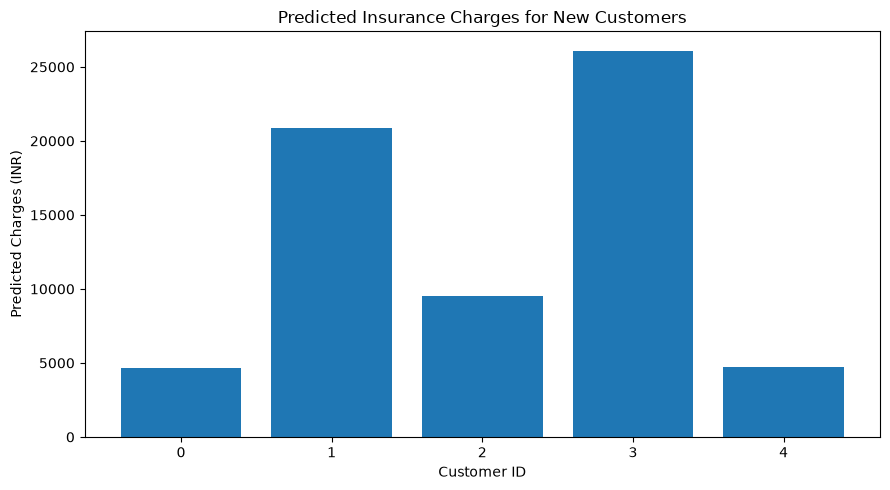

In [104]:
#
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    new_customers.index,
    new_customers["Predicted Charges (INR)"]
)

plt.title("Predicted Insurance Charges for New Customers")
plt.xlabel("Customer ID")
plt.ylabel("Predicted Charges (INR)")
plt.xticks(new_customers.index)
plt.tight_layout()
plt.show()